### Monte Carlo

In [1]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [3]:
# Parameters
ticker = "TCS.NS"  # Change this to any stock ticker
confidence_level = 0.95  # 95% confidence level
num_simulations = 10000  # Number of Monte Carlo simulations
time_horizon = 1  # Days ahead for VaR calculation

In [4]:
stock = yf.Ticker(ticker)
hist = stock.history(period="1y")  # Get 1 year of historical data

In [5]:
returns = hist['Close'].pct_change().dropna()

In [6]:
# Estimate mean and standard deviation of returns
mu = returns.mean()
sigma = returns.std()

In [7]:
# Monte Carlo simulation of stock price paths
last_price = hist['Close'].iloc[-1]
sim_returns = np.random.normal(mu, sigma, num_simulations)
sim_prices = last_price * (1 + sim_returns)

In [8]:
# Calculate VaR at given confidence level
threshold = np.percentile(sim_prices - last_price,
                          (1 - confidence_level) * 100)

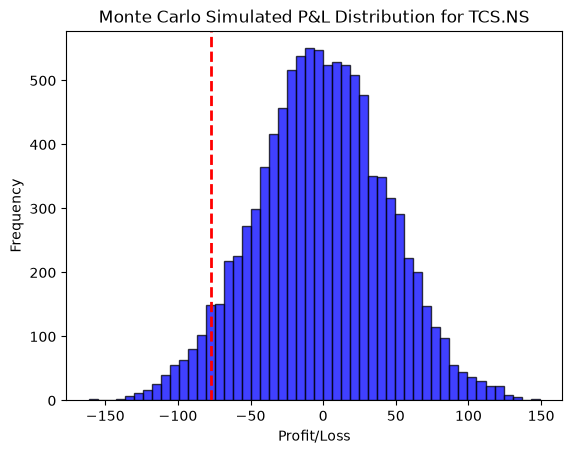

95.0% Monte Carlo VaR for TCS.NS: 77.24


In [10]:
# Plot histogram of simulated returns
plt.hist(sim_prices - last_price, bins=50,
         alpha=0.75, color="blue", edgecolor="black")
plt.axvline(threshold, color="red", linestyle="dashed", linewidth=2)
plt.title(f"Monte Carlo Simulated "
          f"P&L Distribution for {ticker}")
plt.xlabel("Profit/Loss")
plt.ylabel("Frequency")
plt.show()

# Print VaR result
print(f"{confidence_level * 100}% Monte Carlo "
      f"VaR for {ticker}: {-threshold:.2f}")

### Correlation

In [12]:
import numpy as np
import pandas as pd

In [13]:
pd.options.display.float_format = '{:,.5f}'.format
TRADING_DAYS = 252

In [18]:
def collect_prices_returns(tickers: list):
    close_prices = pd.DataFrame()
    log_returns = pd.DataFrame()

    for ticker in tickers:
        close_prices[ticker] = yf.Ticker(ticker).history(
            start='2024-01-01',
            end='2025-12-31',
            interval="1d")['Close']
        log_returns[ticker] = np.log(close_prices[ticker]
                                     / close_prices[ticker].shift(1))
    return close_prices, log_returns

<Axes: >

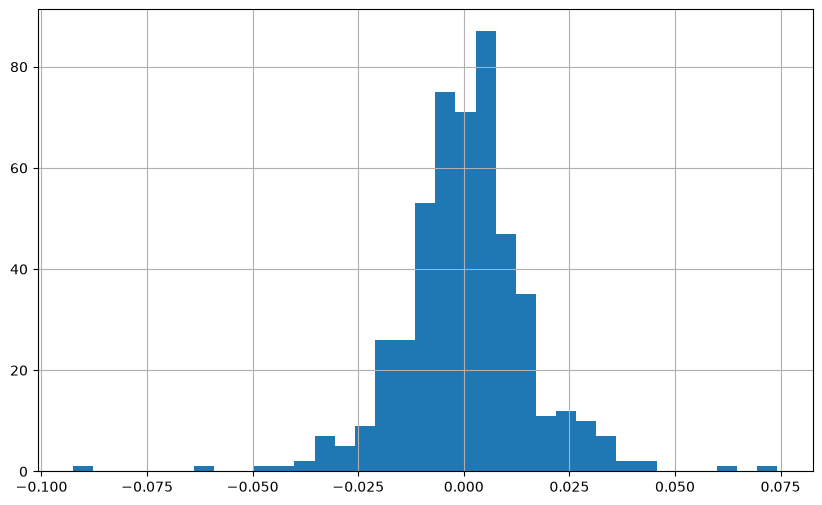

In [19]:
tickers = ["INFY.NS", "HCLTECH.NS", "WIPRO.NS"]
close_prices, log_returns  = collect_prices_returns(tickers)
log_returns["HCLTECH.NS"].hist(bins=35, figsize=(10, 6))

In [20]:
price_stats = close_prices[tickers].agg(['mean', 'std', 'var']).T.reset_index().rename(columns={'index': 'ticker'})
price_stats

,ticker,mean,std,var
0,INFY.NS,"1,565.32434",163.06358,"26,589.73122"
1,HCLTECH.NS,"1,509.79683",146.99794,"21,608.39482"
2,WIPRO.NS,244.06822,20.80551,432.86927


In [21]:
rets = log_returns[tickers].agg(['mean', 'std', 'var']).T * [TRADING_DAYS, TRADING_DAYS**0.5, TRADING_DAYS]
rets = rets.reset_index().rename(columns={'index': 'ticker'})
rets

,ticker,mean,std,var
0,INFY.NS,0.05346,0.23944,0.05733
1,HCLTECH.NS,0.08045,0.24077,0.05797
2,WIPRO.NS,0.07219,0.26733,0.07147


In [22]:
cov_matrix = log_returns.cov() * TRADING_DAYS
cov_matrix

,INFY.NS,HCLTECH.NS,WIPRO.NS
INFY.NS,0.05733,0.03980,0.04024
HCLTECH.NS,0.03980,0.05797,0.03699
WIPRO.NS,0.04024,0.03699,0.07147


In [25]:
close_price, log_returns = collect_prices_returns(["TATASTEEL.NS", "RELIANCE.NS"])
cov_matrix = log_returns.cov() * TRADING_DAYS
print(cov_matrix)
corr_matrix = log_returns.corr()
print(corr_matrix)

              TATASTEEL.NS  RELIANCE.NS
TATASTEEL.NS       0.08395      0.02749
RELIANCE.NS        0.02749      0.04508
              TATASTEEL.NS  RELIANCE.NS
TATASTEEL.NS       1.00000      0.44679
RELIANCE.NS        0.44679      1.00000


### Markowitz

In [26]:
from datetime import datetime, timedelta

In [27]:
def load_stocks(tickers, year_backs):
    start_date = datetime.today() - timedelta(days=365*year_backs)  # 3 years of data
    end_date = datetime.today()
    stock_data = yf.download(tickers, start=start_date, end=end_date)['Close']
    returns = stock_data.pct_change().dropna()
    return returns

In [29]:
tickers = ["TCS.NS", "BRITANNIA.NS", "INFY.NS", "RELIANCE.NS", "CIPLA.NS", "ICICIBANK.NS", "HCLTECH.NS"]
year_backs = 5
returns = load_stocks(tickers, year_backs)

[*********************100%***********************]  7 of 7 completed


In [30]:
risk_free_rate = 0.02
TRADING_DAYS = 252
mean_returns = returns.mean() * TRADING_DAYS  # Annualized mean return
cov_matrix = returns.cov() * TRADING_DAYS  # Annualized covariance matrix

num_portfolios = 10000 # Number of portfolios to simulate
num_assets = len(tickers)

# Storage for portfolio weights, returns, risk, and Sharpe ratios
port_returns = np.zeros(num_portfolios)
port_volatility = np.zeros(num_portfolios)
sharpe_ratios = np.zeros(num_portfolios)
all_weights = np.zeros((num_portfolios, num_assets))

In [31]:
# Monte Carlo simulation for random portfolios
for i in range(num_portfolios):
    weights = np.random.dirichlet(np.ones(num_assets), size=1).flatten()
    all_weights[i, :] = weights
    port_returns[i] = np.dot(weights, mean_returns)
    port_volatility[i] = np.sqrt(np.dot(weights.T,
                                        np.dot(cov_matrix, weights)))
    sharpe_ratios[i] = (port_returns[i] - risk_free_rate) / port_volatility[i]

# Find optimal Sharpe ratio portfolio
max_sharpe_idx = np.argmax(sharpe_ratios)
optimal_weights = all_weights[max_sharpe_idx, :]

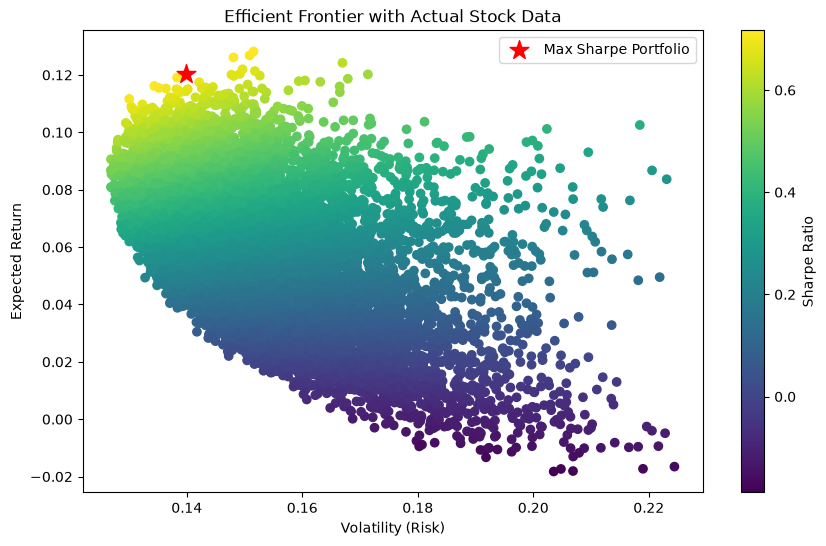

In [32]:
# Plot the Efficient Frontier
plt.figure(figsize=(10, 6))
plt.scatter(port_volatility, port_returns, c=sharpe_ratios,
            cmap='viridis', marker='o')
plt.colorbar(label='Sharpe Ratio')
plt.xlabel('Volatility (Risk)')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier with Actual Stock Data')

# Highlight Maximum Sharpe Ratio Portfolio
plt.scatter(port_volatility[max_sharpe_idx],
            port_returns[max_sharpe_idx],
            c='red', marker='*', s=200,
            label='Max Sharpe Portfolio')
plt.legend()
plt.show()

In [33]:
# Display optimal portfolio weights
optimal_portfolio_df = pd.DataFrame({
    'Stock': tickers,
    'Optimal Weight': optimal_weights
})

print(optimal_portfolio_df)

          Stock  Optimal Weight
0        TCS.NS         0.08750
1  BRITANNIA.NS         0.22878
2       INFY.NS         0.13157
3   RELIANCE.NS         0.49864
4      CIPLA.NS         0.00130
5  ICICIBANK.NS         0.00483
6    HCLTECH.NS         0.04738


### Rebalancing

In [34]:
target_allocation = {
"TCS.NS":        0.016804,
"BRITANNIA.NS":        0.007427,
"INFY.NS":        0.015956,
"RELIANCE.NS":        0.142700,
"CIPLA.NS":        0.193730,
"ICICIBANK.NS":        0.009315,
"HCLTECH.NS":        0.614068
}

In [36]:
current_portfolio = {
"TCS.NS":        100000,
"BRITANNIA.NS":        100000,
"INFY.NS":        100000,
"RELIANCE.NS":        100000,
"CIPLA.NS":        100000,
"ICICIBANK.NS":        100000,
"HCLTECH.NS":        100000,
}

# Define rebalancing threshold (e.g., 5% deviation from target)
threshold = 0.05

# Compute total portfolio value
total_value = sum(current_portfolio.values())

In [37]:
# Compute current allocations
current_allocation = {stock: value / total_value
                      for stock, value
                      in current_portfolio.items()}
current_allocation

{'TCS.NS': 0.14285714285714285,
 'BRITANNIA.NS': 0.14285714285714285,
 'INFY.NS': 0.14285714285714285,
 'RELIANCE.NS': 0.14285714285714285,
 'CIPLA.NS': 0.14285714285714285,
 'ICICIBANK.NS': 0.14285714285714285,
 'HCLTECH.NS': 0.14285714285714285}

In [38]:
# Compute deviations from target allocation
dev = {
    stock: current_allocation[stock]
           - target_allocation[stock]
           for stock in target_allocation
}

# Identify assets that need rebalancing
rebalance_needed = {stock: value
                    for stock, value in dev.items()
                    if abs(value) > threshold}

# Compute necessary buys/sells to rebalance
adjustments = {}
for stock in rebalance_needed:
    target_value = target_allocation[stock] * total_value
    current_value = current_portfolio[stock]
    adjustments[stock] = target_value - current_value  # Positive = buy, Negative = sell

# Display rebalancing actions
rebalance_df = pd.DataFrame({
    "Stock": list(adjustments.keys()),
    "Current Value": [current_portfolio[stock] for stock in adjustments],
    "Target Value": [target_allocation[stock] * total_value for stock in adjustments],
    "Adjustment": [adjustments[stock] for stock in adjustments],
    "Action": ["Buy" if adj > 0 else "Sell" for adj in adjustments.values()]
})

In [39]:
rebalance_df

,Stock,Current Value,Target Value,Adjustment,Action
0,TCS.NS,100000,"11,762.80000","-88,237.20000",Sell
1,BRITANNIA.NS,100000,"5,198.90000","-94,801.10000",Sell
2,INFY.NS,100000,"11,169.20000","-88,830.80000",Sell
3,CIPLA.NS,100000,"135,611.00000","35,611.00000",Buy
4,ICICIBANK.NS,100000,"6,520.50000","-93,479.50000",Sell
5,HCLTECH.NS,100000,"429,847.60000","329,847.60000",Buy


### Simulating Non FInancial Risk

In [41]:
from sklearn.preprocessing import MinMaxScaler

In [42]:
# Step 1: Define synthetic data (representing different risk factors)
data = {
    "Operational Risk": np.random.uniform(0, 100, 10),  # System downtime, security breaches
    "Regulatory Risk": np.random.uniform(0, 100, 10),  # Lawsuits, compliance fines
    "ESG Risk": np.random.uniform(0, 100, 10),         # Environmental, social, governance factors
    "Tech Obsolescence": np.random.uniform(0, 100, 10), # R&D spending, patent filings
    "Political Risk": np.random.uniform(0, 100, 10),    # Country stability, trade restrictions
    "Reputation Risk": np.random.uniform(0, 100, 10),   # Social media sentiment, brand issues
    "Management Risk": np.random.uniform(0, 100, 10)    # CEO turnover, employee satisfaction
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Step 2: Normalize data to a scale of 0 to 100
scaler = MinMaxScaler(feature_range=(0, 100))
df_normalized = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# Step 3: Assign weights to different risk factors (adjust based on importance)
weights = {
    "Operational Risk": 0.15,
    "Regulatory Risk": 0.15,
    "ESG Risk": 0.20,
    "Tech Obsolescence": 0.10,
    "Political Risk": 0.15,
    "Reputation Risk": 0.15,
    "Management Risk": 0.10
}

# Step 4: Compute the weighted sum for overall Non-Financial Risk Score (NFRS)
df_normalized["Non-Financial Risk Score"] = df_normalized.dot(pd.Series(weights))

In [43]:
df_normalized

,Operational Risk,Regulatory Risk,ESG Risk,Tech Obsolescence,Political Risk,Reputation Risk,Management Risk,Non-Financial Risk Score
0,0.00000,78.44364,0.00000,45.84112,76.58123,100.00000,38.92535,46.73038
1,84.29011,2.44760,100.00000,0.00000,100.00000,10.81010,76.99682,57.33185
2,100.00000,0.00000,42.68116,95.79542,18.13425,67.04520,76.27503,53.52020
3,26.51104,18.01269,24.78308,33.55737,19.76528,68.01351,97.43889,37.90162
4,7.91353,58.22453,1.34282,10.38540,29.11994,49.80014,37.23725,26.78955
5,44.73372,20.65198,6.79724,50.91841,11.28761,30.37403,48.87534,27.39592
6,24.22038,100.00000,19.50013,24.83807,7.91182,8.75834,0.00000,27.51741
7,27.74605,51.83207,18.77835,23.41603,0.00000,23.15631,21.03548,23.61098
8,89.42090,47.93407,84.69591,100.00000,46.12834,0.00000,96.03983,64.06566
9,90.59508,71.21068,91.98760,82.55599,62.35259,61.41467,100.00000,79.48907


[*********************100%***********************]  1 of 1 completed
/var/folders/_q/62dl_dyd4tn0gxdgqcwhjnnh0000gn/T/ipykernel_64182/3383048239.py:9: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  data = data.resample('Y').last()  # Get the last value of each year


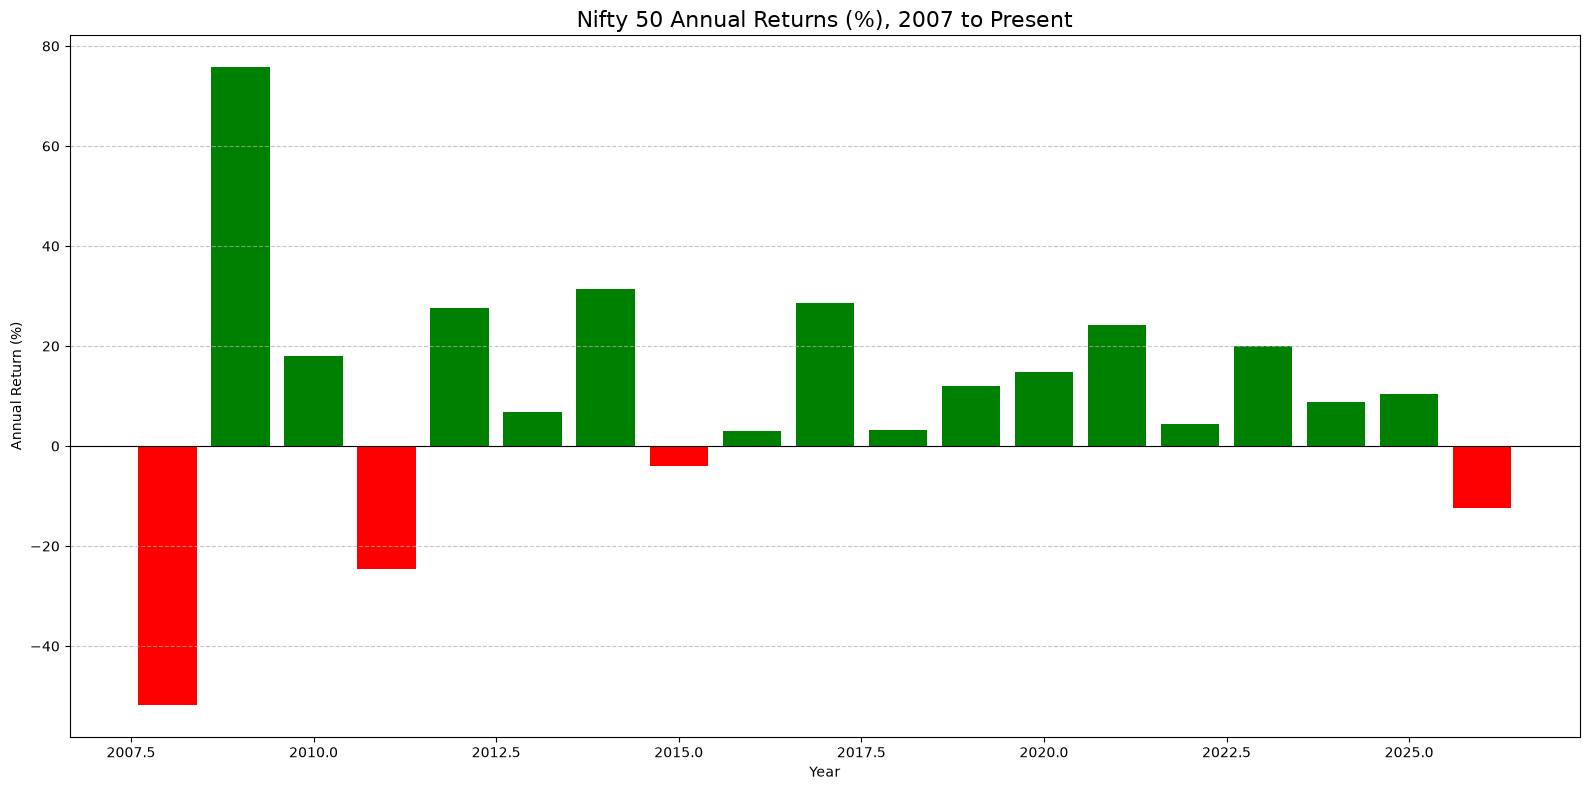

In [44]:
# Download Nifty-50 historical data (earliest possible date to today)
ticker = "^NSEI"
data = yf.download(ticker, start="2007-09-17")  # Yahoo earliest data ~2007

# Extract only the 'Adj Close' price
data = data['Close']

# Calculate annual returns
data = data.resample('Y').last()  # Get the last value of each year
returns = data.pct_change().dropna()

# Prepare DataFrame for plotting
returns_df = pd.DataFrame(returns)
returns_df.columns = ['Annual Return']
returns_df['Year'] = returns_df.index.year

# Plot positive and negative years in different colors
colors = returns_df['Annual Return'].apply(lambda x: 'green' if x > 0 else 'red')

plt.figure(figsize=(16, 8))
plt.bar(returns_df['Year'], returns_df['Annual Return'] * 100, color=colors)
plt.axhline(0, color='black', linewidth=0.8)
plt.title('Nifty 50 Annual Returns (%), 2007 to Present', fontsize=16)
plt.xlabel('Year')
plt.ylabel('Annual Return (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [45]:
returns_df.loc[:, 'Annual Return'].mean()

np.float64(0.10329778085173436)